# Módulo 6 — Decomposição de séries temporais

## Seção 2 — Suavização por regressão local: fundamentos matemáticos de LOWESS e LOESS

**Estado editorial:** material didático para revisão. **Pré-requisitos:** regressão linear e mínimos quadrados (Módulo 2), médias móveis e filtros, noções de função derivável e vetores, NumPy e Matplotlib. **Continuidade:** esta seção fundamenta a suavização usada em STL; **não** apresenta ainda o algoritmo STL completo.

**Origem dos conceitos:** Morettin e Toloi, *Análise de Séries Temporais: Modelos lineares univariados*, v. 1, cap. 3, §3.2, p. 52 (PDF p. 71), lista a suavização mediante ajustes sucessivos de retas de mínimos quadrados ponderados (*lowess*) como uma via para estimar tendência; §3.2.2, pp. 55–56 (PDF pp. 74–75) oferece a referência para filtros de média móvel. **A dedução das equações de mínimos quadrados locais, o núcleo tricúbico, os testes, o código e os exercícios são complementações matemáticas e computacionais**; não são atribuídos às páginas consultadas. O mapeamento do curso identifica LOESS/STL/MSTL na *Aula 2 — Parte II* como referência pedagógica, sem substituir uma exposição formal.

### Objetivos

Explicar por que uma média móvel pode introduzir viés em regiões curvadas; formular uma regressão **local**; deduzir estimativas por mínimos quadrados ponderados; construir pesos por distância; calcular manualmente uma regressão com três pontos; programar um suavizador local simples; comparar com `statsmodels.nonparametric.lowess`; estudar escolha de largura, bordas, robustez e risco de vazamento temporal.

### 1. Problema: média móvel versus regressão local

Um filtro de média móvel centrada estima o nível como média ponderada:

$$
\widehat T(t_0)=\sum_{i=1}^{n}w_i(t_0)z_i,
\qquad \sum_iw_i(t_0)=1.
$$

Ele se comporta bem sobre funções constantes, mas sua capacidade de acompanhar uma inclinação ou curvatura depende dos pesos. Em uma regressão **local**, aproximamos a função de tendência **perto de cada instante-alvo** por uma reta ou um polinômio pequeno; observações próximas recebem pesos maiores. Refazemos o ajuste para cada $t_0$. Diferentemente de ajustar um polinômio global, os parâmetros locais podem mudar quando deslocamos o centro.

O nome **LOWESS** costuma referir-se a *locally weighted scatterplot smoothing* e geralmente a regressão local linear. **LOESS**, em uso mais amplo, permite também ajustes locais de grau 2. Na prática, as nomenclaturas e rotinas variam; ao documentar um método, declare grau, função de pesos, tamanho de vizinhança e iterações robustas.

### 2. Ajuste de uma reta em torno de $t_0$

Defina $u_i=t_i-t_0$ (distância **assinada** ao centro) e ajuste

$$
\boxed{z_i\approx a(t_0)+b(t_0)u_i.}
$$

Por construção, o valor estimado exatamente no centro é $\widehat T(t_0)=\widehat a(t_0)$, pois $u=0$. Esta centralização simplifica a interpretação: $a$ é o nível local e $b$ é a inclinação local.

Escolhendo pesos $w_i\ge0$, minimizamos

$$
Q_{t_0}(a,b)=\sum_{i=1}^n w_i(t_0)\,[z_i-a-bu_i]^2.
$$

Aqui $w_i$ representa proximidade/importância **para aquele ajuste**, não uma probabilidade nem uma variância necessariamente conhecida. O número de observações com peso positivo precisa ser suficiente para identificar os coeficientes.

### 3. Derivação integral das equações normais ponderadas

Derive a função objetivo em relação a $a$:

$$
\frac{\partial Q}{\partial a}=-2\sum_iw_i(z_i-a-bu_i)=0.
$$

Em relação a $b$:

$$
\frac{\partial Q}{\partial b}=-2\sum_iw_iu_i(z_i-a-bu_i)=0.
$$

Defina os cinco somatórios

$$
S_0=\sum_iw_i,\quad S_1=\sum_iw_iu_i,\quad S_2=\sum_iw_iu_i^2,
$$

$$
R_0=\sum_iw_iz_i,\qquad R_1=\sum_iw_iu_iz_i.
$$

As condições de ótimo podem ser escritas na forma matricial

$$
\boxed{\begin{pmatrix}S_0&S_1\\S_1&S_2\end{pmatrix}
\begin{pmatrix}\widehat a\\\widehat b\end{pmatrix}
=\begin{pmatrix}R_0\\R_1\end{pmatrix}.}
$$

O determinante é $D=S_0S_2-S_1^2$. Se $D>0$, a matriz é definida positiva e existe um único mínimo:

$$
\boxed{\widehat a=\frac{S_2R_0-S_1R_1}{D},\qquad
\widehat b=\frac{S_0R_1-S_1R_0}{D}.}
$$

**Interpretação de $D$:** com pesos positivos, a identidade $D=S_0\sum_iw_i(u_i-\bar u_w)^2$, onde $\bar u_w=S_1/S_0$, mostra que $D>0$ requer instantes distintos com peso positivo. Quando todos os pontos efetivos têm o mesmo tempo, a reta não é identificável.

Escrevendo $X=[\mathbf1,\mathbf u]$, $W=\operatorname{diag}(w_1,\ldots,w_n)$ e $\boldsymbol\beta=(a,b)^\top$, obtemos $X^\top WX\widehat{\boldsymbol\beta}=X^\top W\mathbf z$. Em Python é preferível resolver um problema de mínimos quadrados em $\sqrt W X$ e $\sqrt W\mathbf z$, em vez de inverter explicitamente $X^\top WX$.

### 4. Exemplo numérico resolvido: três pontos e pesos diferentes

Temos dados fictícios $(t_i,z_i)=(0,2),(1,3),(2,6)$; queremos estimar o valor no centro $t_0=1$ e escolhemos pesos $(1,2,1)$, privilegiando a observação central. Portanto,

$$
(u_1,u_2,u_3)=(-1,0,1),\qquad(w_1,w_2,w_3)=(1,2,1).
$$

Calculemos cada soma:

$$
S_0=1+2+1=4,\quad S_1=-1+0+1=0,\quad S_2=1+0+1=2,
$$

$$
R_0=1(2)+2(3)+1(6)=14,\quad
R_1=(-1)(2)+0(3)+(1)(6)=4.
$$

Como $D=4(2)-0=8>0$,

$$
\boxed{\widehat a=\frac{2(14)}8=3{,}5,\qquad
\widehat b=\frac{4(4)}8=2.}
$$

A reta local é $\widehat z(t)=3{,}5+2(t-1)$. No centro, o suavizador fornece $\widehat T(1)=3{,}5$. O valor observado no centro é 3: **suavização não significa interpolação**. A média ponderada dos três valores também é $3{,}5$ neste exemplo simétrico, porque $S_1=0$; fora desse caso, a estimativa linear local pode diferir da média ponderada.

### 5. Como construir os pesos: vizinhança e núcleo tricúbico

Em geral selecionamos uma proporção $q\in(0,1]$ dos dados mais próximos de $t_0$, correspondendo a $k=\lceil qn\rceil$ observações, com $k$ suficiente para o grau escolhido. Seja $d_i=|t_i-t_0|$ e $h(t_0)$ uma distância de escala positiva, usualmente associada ao $k$-ésimo vizinho. Um núcleo **tricúbico** é

$$
\boxed{K(v)=\begin{cases}(1-|v|^3)^3,&|v|<1,\\0,&|v|\ge1.\end{cases}}
$$

Definimos $w_i(t_0)=K(d_i/h(t_0))$. Se o ponto está no centro, o peso é máximo; à medida que a distância se aproxima da borda de suporte, o peso diminui até zero. **Escolha de borda:** se tomarmos literalmente $h$ como distância do $k$-ésimo vizinho, os pontos situados exatamente em $h$ recebem peso zero. Implementações práticas podem ajustar $h$ ou o procedimento para alcançar a quantidade desejada de pontos efetivos, e empates de distância exigem uma convenção. Isso importa sobretudo em amostras curtas e dados duplicados.

Para o nosso código didático, construiremos $h$ como a distância ao $k$-ésimo vizinho **multiplicada por $(1+10^{-9})$**, para incluir positivamente esse vizinho quando possível. A rotina conserva a exigência de dois instantes distintos com peso positivo; a opção didática não pretende reproduzir exatamente todos os detalhes de bibliotecas consolidadas.

### 6. Por que a reta local reproduz linhas retas?

Suponha que não haja ruído e que $z_i=c+dt_i$. Com $u_i=t_i-t_0$:

$$
z_i=(c+dt_0)+du_i.
$$

Assim, os coeficientes $a=c+dt_0$ e $b=d$ tornam **todos os resíduos zero** e minimizam $Q$. Se $D>0$, a solução é única. Portanto, a regressão local de grau 1 reproduz uma reta exatamente **mesmo com pesos assimétricos na borda**. Esse resultado explica uma vantagem sobre uma média móvel unilateral simples, que costuma introduzir defasagem em tendências crescentes.

Para uma curva quadrática $z_i=c+dt_i+et_i^2$, uma reta local, em geral, apresenta erro de aproximação. Uma regressão local **quadrática** pode eliminar esse erro algébrico em dados sem ruído, desde que a matriz de desenho tenha posto 3. Entretanto, graus maiores aumentam a sensibilidade a amostras pequenas e ao condicionamento da regressão.

### 7. Python — implementar primeiro, depois comparar com Statsmodels

A implementação a seguir usa NumPy para manipular as observações, `np.linalg.lstsq` para resolver mínimos quadrados ponderados, e a rotina `lowess` de Statsmodels para comparação de forma **qualitativa**. Em particular, `it=0` desativa as reponderações robustas adicionais; mesmo assim os resultados numéricos podem diferir em detalhes de largura, tratamento de vizinhos e empates.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

# Implementação didática: sem detecção automática de dados ausentes
# e com tempos distintos e ordenados.
def loess_linear_manual(t, z, frac=0.25):
    t = np.asarray(t, dtype=float)
    z = np.asarray(z, dtype=float)
    if t.ndim != 1 or z.ndim != 1 or len(t) != len(z):
        raise ValueError('t e z devem ter o mesmo comprimento.')
    if len(t) < 3 or not (0 < frac <= 1):
        raise ValueError('Amostra curta ou fração fora do intervalo.')
    if not (np.all(np.isfinite(t)) and np.all(np.isfinite(z))):
        raise ValueError('Remova ou trate explicitamente valores ausentes.')
    if not np.all(np.diff(t) > 0):
        raise ValueError('Esta versão exige tempos estritamente crescentes.')
    n = len(t)
    k = max(3, int(np.ceil(frac*n)))
    saida = np.empty(n)
    for i, alvo in enumerate(t):
        u = t - alvo
        d = np.abs(u)
        h = np.partition(d, k-1)[k-1] * (1 + 1e-9)
        w = np.maximum(0, 1 - (d/h)**3)**3
        X = np.column_stack([np.ones(n), u])
        coef, *_ = np.linalg.lstsq(X*np.sqrt(w[:, None]),
                                   z*np.sqrt(w), rcond=None)
        saida[i] = coef[0]
    return saida

rng = np.random.default_rng(20261119)
t = np.arange(120, dtype=float)
tendencia = 3 + 0.025*t + 2*np.sin(2*np.pi*t/80)
z = tendencia + rng.normal(0, 0.55, len(t))
manual = loess_linear_manual(t, z, frac=0.25)
biblioteca = lowess(z, t, frac=0.25, it=0,
                    return_sorted=False, delta=0)

print('Erro quadrático médio da suavização manual contra verdade simulada:',
      np.mean((manual - tendencia)**2))
print('Maior diferença manual versus biblioteca:',
      np.max(np.abs(manual - biblioteca)))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(t, z, '.', alpha=0.45, label='Dados simulados')
ax.plot(t, tendencia, '--', lw=2, label='Tendência verdadeira')
ax.plot(t, manual, lw=2, label='Regressão local manual')
ax.plot(t, biblioteca, ':', lw=2, label='Statsmodels LOWESS (it=0)')
ax.set(xlabel='Instante t', ylabel='Valor', title='Suavização local linear')
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

**Operações essenciais:** `np.partition(d, k-1)[k-1]` identifica a distância ao vizinho da ordem escolhida; `np.maximum(0, ·)` evita pesos negativos fora do suporte; `np.column_stack` monta o intercepto e o tempo centrado; `np.sqrt(w)` aplica corretamente os pesos ao problema de mínimos quadrados, pois $\|\sqrt W(X\beta-z)\|_2^2=\sum_iw_i(X_i\beta-z_i)^2$. O código usa `frac` como fração da amostra, **não** como duração temporal fixa.

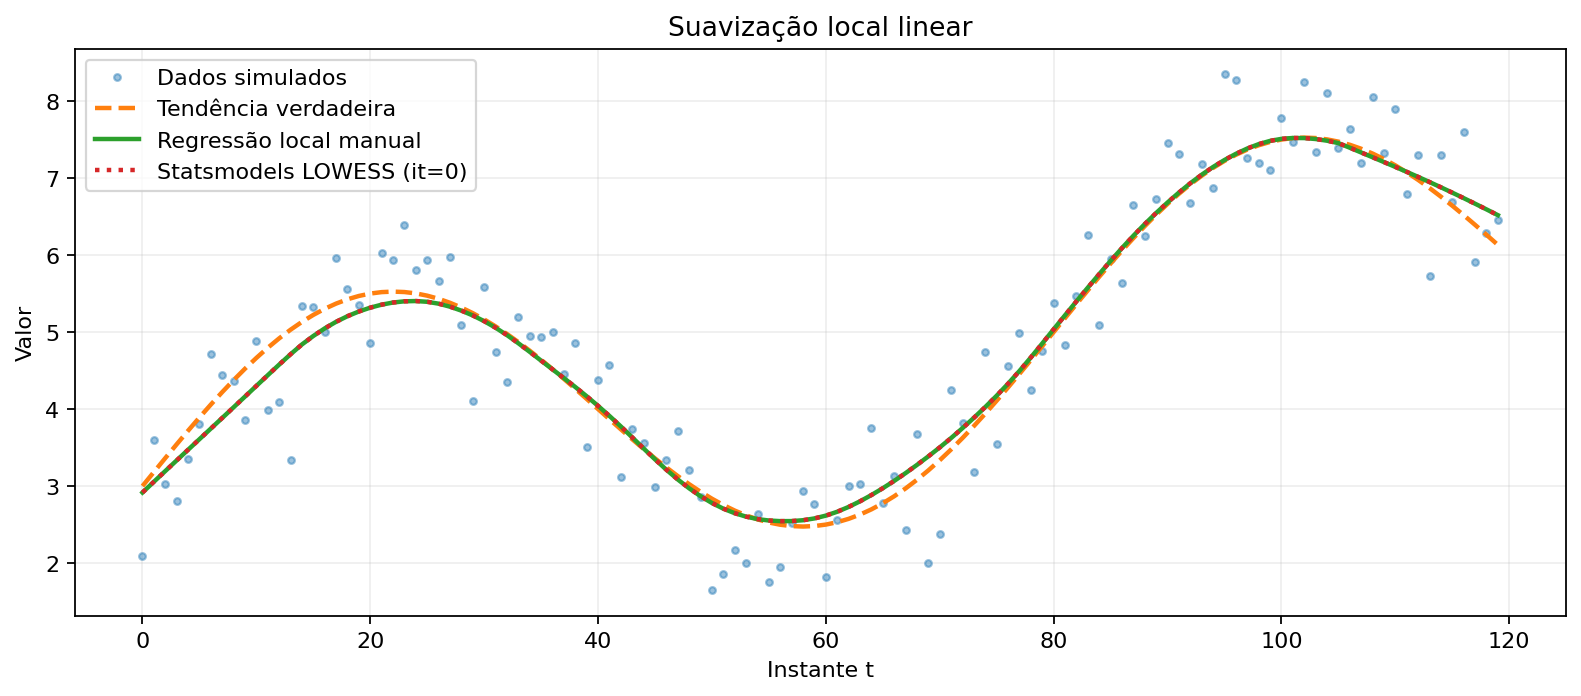

*Figura 6.2 — Realização simulada, tendência determinística conhecida e estimativas por regressão local. A diferença entre a curva manual e a do Statsmodels informa detalhes de implementação; a coincidência exata não é uma propriedade matemática exigida.*

### 8. Largura da vizinhança: viés e variabilidade

Uma vizinhança muito pequena produz estimativas que reagem fortemente ao ruído. Uma vizinhança muito grande suaviza picos e vales genuínos e pode distorcer mudanças de tendência. É o **compromisso viés–variância**: reduzir variabilidade pelo uso de mais observações pode aumentar o erro sistemático de aproximação local.

In [ ]:
curto = loess_linear_manual(t, z, frac=0.10)
medio = loess_linear_manual(t, z, frac=0.25)
longo = loess_linear_manual(t, z, frac=0.60)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t, z, '.', alpha=0.22, label='Série')
for y, lab in [(curto, 'fração 0,10'),
               (medio, 'fração 0,25'),
               (longo, 'fração 0,60')]:
    ax.plot(t, y, label=lab)
ax.plot(t, tendencia, '--', color='black', label='Tendência verdadeira')
ax.legend()
ax.set(xlabel='Instante t', ylabel='Valor', title='Efeito do tamanho da vizinhança')
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

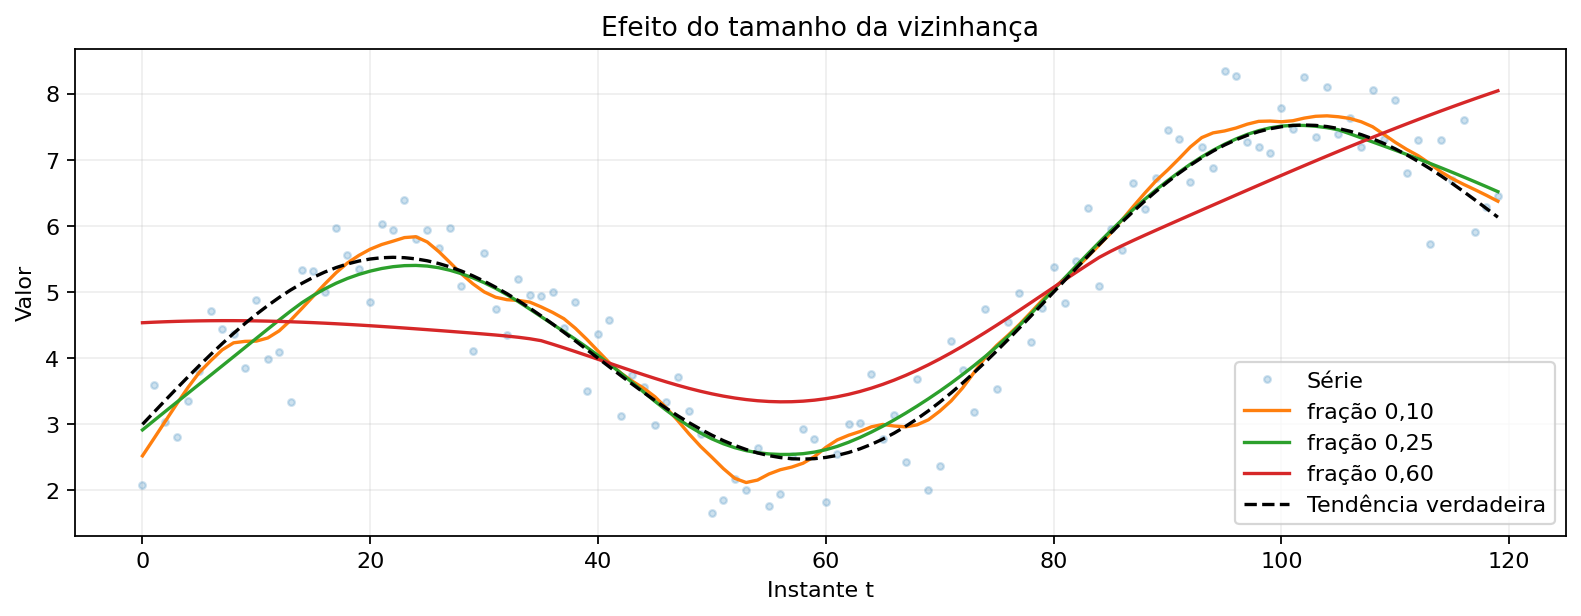

*Figura 6.3 — A vizinhança curta acompanha alterações rápidas e ruído; a larga produz uma trajetória mais suave, mas pode distorcer a curvatura. O parâmetro ideal depende do objetivo e não se deduz deste gráfico isoladamente.*

### 9. Robustez: por que são necessárias reponderações?

A função tricúbica controla a **distância temporal**, mas não impede que uma observação próxima seja um valor extremo e distorça a reta local. Algoritmos robustos como o LOWESS com iterações adicionais podem diminuir a influência de resíduos grandes usando uma segunda família de pesos dependente dos resíduos. Uma escolha conhecida é o peso biesquadrado, para $|r_i|/c<1$:

$$
w_i^{(r)}=\bigl[1-(r_i/c)^2\bigr]^2,
$$

com peso zero fora desse intervalo, em que $c$ é uma escala robusta como um múltiplo da mediana dos resíduos absolutos. O peso total torna-se $w_i^{(\text{dist})}w_i^{(r)}$. O objetivo não é afirmar que todo valor extremo seja um erro: **choques reais, mudanças abruptas e eventos raros** também podem precisar de representação explícita. A regra exata de escala e de atualização depende da implementação.

In [ ]:
z_outlier = z.copy()
z_outlier[55] += 9
comum = lowess(z_outlier, t, frac=0.25, it=0,
                return_sorted=False, delta=0)
robusto = lowess(z_outlier, t, frac=0.25, it=3,
                 return_sorted=False, delta=0)
print('Estimativas no instante do pico:', comum[55], robusto[55])

`it=3` ativa reponderações robustas na rotina da biblioteca; isso não equivale a remover o ponto de seus dados. A robustez pode ser desejável para estimar tendências sob contaminação, mas pode **esconder uma quebra estrutural verdadeira** quando aplicada sem investigação.

### 10. Por que o LOESS prepara o STL, mas não é o STL?

A suavização local estima uma curva em função do tempo. O **STL** (*Seasonal-Trend decomposition using LOESS*) utiliza suavizações locais dentro de um algoritmo iterativo específico para separar tendência e componente sazonal variável ao longo do tempo, além de um componente restante. Um simples ajuste `lowess(z,t)` diretamente na série com sazonalidade pode misturar componentes: não recupera, por si só, a decomposição STL.

Na próxima seção será necessário desenvolver, separadamente, suavizações sazonais por sub-séries, extração da tendência, filtros de baixa passagem e laços internos/externos de atualização. **MSTL**, por sua vez, amplia o cenário para múltiplos períodos sazonais e ainda exige decisões sobre interações entre ciclos.

### 11. Limitações e método científico

**Estabilidade numérica:** a regressão local pode ficar quase singular em vizinhanças pequenas ou com tempos repetidos; por isso implementamos `lstsq` e validamos os tempos. **Bordas:** a suavização local usa vizinhanças assimétricas; a regressão reproduz retas, mas pode distorcer curvaturas e ter maior variabilidade. **Dados ausentes:** a rotina didática não interpola falhas; a qualidade da amostra precisa ser tratada antes. **Espaçamento temporal:** a função de distância deve corresponder ao calendário efetivo, não somente à posição do vetor, quando intervalos forem desiguais. **Inferência:** a suavização não gera automaticamente intervalos preditivos ou testes de tendência; seus graus de liberdade efetivos dependem dos pesos. **Vazamento temporal:** regressões locais centradas usam pontos futuros para estimar o passado. Se a finalidade é previsão, adapte o filtro para utilizar só informações disponíveis na origem, reestimando em cada divisão cronológica. **Método versus fenômeno:** valores extremos e mudanças reais não podem ser eliminados sem justificativa substantiva.

### 12. Exercícios graduais

1. **Derivação:** partindo de $Q(a,b)$, desenvolva as duas derivadas parciais e recupere a matriz $2\times2$ das equações normais.
2. **Numérico:** repita o exemplo de três pontos com pesos iguais $(1,1,1)$. Compare o intercepto local com o caso $(1,2,1)$.
3. **Demonstração:** prove que uma função linear em $t$ é reproduzida exatamente por uma regressão local linear quando a matriz tem posto completo.
4. **Python guiado:** escreva um pseudocódigo da rotina `loess_linear_manual` sem copiar o código. Identifique como escolher $k$, $h$, os pesos e as equações ponderadas.
5. **Experimento:** altere `frac` entre 0,10 e 0,60 e compare o erro quadrático médio contra a verdade simulada. Explique por que não há um valor universal ótimo.
6. **Diagnóstico:** injete um ponto anômalo com `z[55] += 9` e compare `it=0` e `it=3`. Que pergunta científica seria necessária antes de classificar o ponto como contaminação?
7. **Pesquisa:** explique por que um LOESS calculado com a série completa não é automaticamente válido para avaliar previsões em um conjunto de teste posterior.

**Pistas:** no exercício 2, os pesos iguais ainda geram $S_1=0$, mas $\widehat a=(2+3+6)/3=11/3\approx3{,}6667$. No exercício 3, apresente os coeficientes que produzem resíduos exatamente nulos.

### 13. Síntese e referências

A suavização LOESS reconstrói uma função por regressões polinomiais **locais** com pesos dependentes da distância ao ponto-alvo. As equações normais mostram de onde vem a estimativa. A escolha da largura e da robustez determina o equilíbrio entre flexibilidade, variabilidade e sensibilidade a extremos. Ela é componente conceitual do STL, mas não substitui a decomposição sazonal completa.

**Fonte acadêmica conferida:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos lineares univariados*, v. 1, 3ª ed., cap. 3, §3.2, p. 52 (item iii, *lowess*), e §3.2.2, pp. 55–56, páginas visualmente conferidas no PDF fornecido. **Fonte pedagógica:** `mapeamento-conteudos-series-temporais.md`, *Aula 2 — Parte II: STL e MSTL*. **Complementações didáticas:** equações ponderadas, tricúbica, exemplo numérico, escolhas de vizinhança, robustez, códigos e exercícios. Não foi verificada uma dedução algorítmica integral do STL ou do MSTL nessas páginas; tal conteúdo será desenvolvido no capítulo seguinte mediante fontes metodológicas adequadas.